# 3.2.2 MPD: CO₂/propane in MOR (Sharma et al. 2023)

Reads `sharma/` (see its README): the binary 300 K distribution from the N-d TMMC ln Π
(`sharma/lnpi_co2_propane_mor_300K_nd_tmmc_walks.txt`, written for RUPTURA by `sharma/mpd/build_nd_tmmc_distribution.py`),
the one-component distributions from the RASPA3 TMMC windows in `sharma/tmmc/` (temperature reweighting, B-PHY-1), and
the RUPTURA runs in `sharma/runs/`. Panels: pure components against the Table 3 fits, the sampled domain of the
distribution, the equimolar mixture and the breakthrough of Fig. 10a with MPD, SIAST, and IAST, and the reweighting of
the pure components from 300 to 350 K. MPD curves are pale where the edge of the sampled domain carries more than
`FRONTIER_LIMIT` of the probability, the trust criterion of the ln Π file. The paper panels are written to
`ruptura-2.0-paper/figures/mpd_mor/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
REPOSITORY = ROOT.parent.parent
SHARMA = ROOT / "sharma"
if not (SHARMA / "runs" / "mixture_equimolar_SIAST").is_dir():
    raise FileNotFoundError("Run this notebook from validation/3.2.2_mpd after sharma/runs/generate.py and run.py.")
RUNS = SHARMA / "runs"
WINDOWS = SHARMA / "tmmc" / "T300K"
LNPI = SHARMA / "lnpi_co2_propane_mor_300K_nd_tmmc_walks.txt"
# trust criterion of the ln Pi file: the states on the edge of the sampled domain carry less than this probability
FRONTIER_LIMIT = 1.0e-3
FIGURE_DIR = REPOSITORY / "ruptura-2.0-paper" / "figures" / "mpd_mor"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

COMPONENTS = {"CO2": 1, "C3H8": 2}
LABELS = {"CO2": "CO$_2$", "C3H8": "C$_3$H$_8$"}
COLORS = {"CO2": "C0", "C3H8": "C1"}
TABLE_3 = {"CO2": [(1.60, 2.617e-4), (3.62, 4.859e-7)], "C3H8": [(1.73, 6.506e-9), (1.09, 2.376e-4)]}
MOLECULES_PER_LOADING = 16 * (48 * 28.0855 + 96 * 15.9994) * 1.0e-3  # molecules in the box per mol/kg
N_TOTAL_MAX, N_PROPANE_MAX = 200, 100
# above these molecule numbers the one-component windows are no longer flat; at 350 K, the propane window 0-42 has a link
# without recorded insertions at 32 -> 33
SAMPLED_MOLECULES_350K = {"CO2": 160, "C3H8": 32}
BOLTZMANN = 1.380649e-23

plt.rcParams.update({
    "figure.figsize": (8, 6),
    # The panels are printed at 0.49 of the A4 text width (3.07 in), i.e. at 38% of their 8 in width.
    # These sizes print as 8.1 pt (ticks, legends) and 8.8 pt (axis labels).
    "font.size": 23,
    "axes.labelsize": 23,
    "axes.titlesize": 25,
    "xtick.labelsize": 21,
    "ytick.labelsize": 21,
    "legend.fontsize": 21,
    "legend.title_fontsize": 21,
    "axes.labelpad": 6.0,
    "lines.linewidth": 3.0,
    "lines.markersize": 10,
    "lines.markeredgewidth": 1.8,
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "legend.handlelength": 1.6,
    "legend.labelspacing": 0.3,
    "legend.borderaxespad": 0.3,
    "legend.columnspacing": 1.0,
    "axes.grid": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
})

## Data handling

In [2]:
def mixture(run, component):
    """Pressure [Pa], pure and mixture loading [mol/kg] of one component of a RUPTURA mixture prediction."""
    index = 1 if run.startswith("pure_") else COMPONENTS[component]
    data = np.loadtxt(RUNS / run / f"component_{index}_{component}.data", ndmin=2)
    return data[:, 0], data[:, 1], data[:, 2]


def langmuir(component, pressure):
    """Dual-site Langmuir fit of Table 3 [mol/kg]."""
    return sum(q * k * pressure / (1.0 + k * pressure) for q, k in TABLE_3[component])


def outlet(run, component):
    """Time [s] and outlet concentration relative to the feed of one component of a RUPTURA breakthrough."""
    data = np.loadtxt(RUNS / run / f"component_{COMPONENTS[component]}_{component}.data", usecols=(1, 2, 3))
    rows = data[data[:, 1] == data[:, 1].max()]
    feed = 0.1 * 1.0e5 / (8.314462618 * 300.0)
    return rows[:, 0] * 60.0, rows[:, 2] / feed


def reweight_pure(component, temperature, reference_temperature, fugacities, with_temperature_term):
    """Loading [mol/kg] from the one-component distribution of reference_temperature, reweighted to temperature.

    First order in 1/T as in RUPTURA; with_temperature_term adds N ln(T_ref/T), as RUPTURA does (B-PHY-1).
    """
    settings = json.loads((SHARMA / "mpd" / f"particle_distribution_T{reference_temperature:.0f}K_{component}.json").read_text())
    data = np.loadtxt(SHARMA / "mpd" / settings["FileName"])
    log_probability = np.log(np.maximum(data[:, 0], 1.0e-320))
    molecules = np.arange(len(data))
    log_weight = log_probability - data[:, 1] / BOLTZMANN * (1.0 / temperature - 1.0 / reference_temperature)
    if with_temperature_term:
        log_weight = log_weight + molecules * np.log(reference_temperature / temperature)
    loadings = []
    for fugacity in fugacities:
        weight = log_weight + molecules * np.log(fugacity / settings["ReferenceFugacity"])
        probability = np.exp(weight - weight.max())
        loadings.append((probability * molecules).sum() / probability.sum())
    return np.array(loadings) / MOLECULES_PER_LOADING


def statistics(directory):
    """Rows of tmmc_statistics.txt; columns 1 CM[-1], 3 CM[+1], 5 ln Pi, 8 histogram."""
    lines = (directory / "tmmc" / "tmmc_statistics.txt").read_text().splitlines()
    header = next(i for i, line in enumerate(lines) if line.startswith("N CM[-1]"))
    return np.array([[float(x) for x in line.split()] for line in lines[header + 1:] if line.strip()])


# the N-d TMMC states: n, m, ln Pi at f = 1e5 Pa for both components, frontier flag, visits
ND_STATES = np.loadtxt(LNPI, comments="#")


def frontier_probability(fugacity_co2, fugacity_propane):
    """Probability of the states on the edge of the sampled domain (frontier = 1) at the fugacities [Pa]."""
    n, m, lnpi, frontier = ND_STATES[:, 0], ND_STATES[:, 1], ND_STATES[:, 2], ND_STATES[:, 4] == 1
    compatible = ((n == 0) | (fugacity_co2 > 0.0)) & ((m == 0) | (fugacity_propane > 0.0))
    weight = lnpi + n * np.log(max(fugacity_co2, 1.0e-300) / 1.0e5) + m * np.log(max(fugacity_propane, 1.0e-300) / 1.0e5)
    probability = np.exp(np.where(compatible, weight, -np.inf) - weight[compatible].max())
    return probability[frontier].sum() / probability.sum()


def ros34pw2_steps(run):
    """Steps of a ROS34PW2 breakthrough, from its run.log."""
    line = next(line for line in (RUNS / run / "run.log").read_text().splitlines() if line.strip().startswith("steps:"))
    return int(line.split()[-1])


## Numbers used in the text

In [3]:
print("Trusted range of the N-d distribution (frontier probability below FRONTIER_LIMIT)")
pressures = np.logspace(2, 8, 601)
for label, (y_co2, y_propane) in {"equimolar": (0.5, 0.5), "pure CO2": (1.0, 0.0), "pure C3H8": (0.0, 1.0)}.items():
    trusted = np.array([frontier_probability(y_co2 * p, y_propane * p) for p in pressures]) < FRONTIER_LIMIT
    print(f"  {label:9s}: trusted up to {pressures[trusted].max():.3g} Pa")
n_states, frontier_states = len(ND_STATES), int((ND_STATES[:, 4] == 1).sum())
print(f"  {n_states} states, {frontier_states} on the edge; visits {ND_STATES[:, 8].min():.0f} to {ND_STATES[:, 8].max():.0f}")
print(f"  breakthrough feed (1e4 Pa each): frontier probability {frontier_probability(1.0e4, 1.0e4):.1e}")

print("Pure components from the binary distribution against Table 3 (and the GCMC of sharma/README.md at 1e4 Pa)")
for component, fractions in {"CO2": (1.0, 0.0), "C3H8": (0.0, 1.0)}.items():
    pressure, _, loading = mixture(f"mixture_pure_{component}_MPD", component)
    trusted = np.array([frontier_probability(fractions[0] * p, fractions[1] * p) for p in pressure]) < FRONTIER_LIMIT
    deviation = 100.0 * (loading / langmuir(component, pressure) - 1.0)
    print(f"  {component}: trusted up to {pressure[trusted].max():.3g} Pa ({loading[trusted].max():.2f} mol/kg), deviation "
          f"from the fit {deviation[trusted].min():+.1f} to {deviation[trusted].max():+.1f} %; above 1e3 Pa "
          f"{deviation[trusted & (pressure >= 1e3)].min():+.1f} to {deviation[trusted & (pressure >= 1e3)].max():+.1f} %")
    for target in [1e2, 1e3, 1e4, 1e5, 1e6]:
        q = np.interp(target, pressure, loading)
        print(f"    {target:8.0e} Pa: {q:6.3f} mol/kg ({q * MOLECULES_PER_LOADING:6.1f} molecules), "
              f"fit {langmuir(component, target):6.3f}, {100.0 * (q / langmuir(component, target) - 1.0):+6.1f} %")

print("Equimolar mixture: MPD against SIAST and IAST in the trusted range")
pressure, _, mpd_co2 = mixture("mixture_equimolar_MPD", "CO2")
_, _, mpd_propane = mixture("mixture_equimolar_MPD", "C3H8")
trusted = np.array([frontier_probability(0.5 * p, 0.5 * p) for p in pressure]) < FRONTIER_LIMIT
for method in ["SIAST", "IAST"]:
    _, _, co2 = mixture(f"mixture_equimolar_{method}", "CO2")
    _, _, propane = mixture(f"mixture_equimolar_{method}", "C3H8")
    for label, mpd, other in [("CO2", mpd_co2, co2), ("C3H8", mpd_propane, propane)]:
        ratio = 100.0 * (mpd[trusted] / other[trusted] - 1.0)
        print(f"  MPD/{method} - 1, {label:4s}: {ratio.min():+6.1f} to {ratio.max():+6.1f} %")
    for target in [1e2, 1e3, 1e4, 1e5, 1e6, 1e7]:
        i = np.argmin(np.abs(pressure - target))
        print(f"    {pressure[i]:8.0e} Pa: MPD {mpd_co2[i]:.3f} {mpd_propane[i]:.3f}, {method} {co2[i]:.3f} {propane[i]:.3f} mol/kg; "
              f"selectivity CO2/C3H8 MPD {mpd_co2[i] / mpd_propane[i]:.2f}, {method} {co2[i] / propane[i]:.2f}")

print("Pure-component windows: visits per state, min and max, and the fraction of states below 1 % of the max")
for pattern in ["slice_C3H8_000_CO2_N*", "edge_C3H8_N*"]:
    for directory in sorted(WINDOWS.glob(pattern)):
        window = statistics(directory)
        print(f"  {directory.name:32s} {window[:, 8].min():9.0f} {window[:, 8].max():9.0f}  "
              f"{(window[:, 8] < 0.01 * window[:, 8].max()).mean():.2f}")

window = statistics(WINDOWS / "slice_C3H8_000_CO2_N000-042")
total = window[:, 1] + window[:, 2] + window[:, 3]
print("Pure CO2, deletion acceptance and visits, N = 32..40:")
for row, sum_row in zip(window[32:41], total[32:41]):
    print(f"  N = {row[0]:3.0f}: {row[1] / sum_row:.2e}, {row[8]:7.0f} visits")

print("Temperature reweighting 300 K -> 350 K against the 350 K distribution")
for component in COMPONENTS:
    pressure, _, direct = mixture(f"pure_{component}_MPD_T350K_ref350K", component)
    _, _, ruptura = mixture(f"pure_{component}_MPD_T350K_ref300K", component)
    with_term = reweight_pure(component, 350.0, 300.0, pressure, True)
    without_term = reweight_pure(component, 350.0, 300.0, pressure, False)
    trusted = direct * MOLECULES_PER_LOADING <= SAMPLED_MOLECULES_350K[component]
    print(f"  {component}: max |RUPTURA - Python, with the term| = {np.abs(ruptura - with_term).max():.1e} mol/kg; "
          f"trusted up to {pressure[trusted].max():.3g} Pa")
    print(f"    with the term: {100.0 * (with_term[trusted] / direct[trusted] - 1.0).min():+.1f} to "
          f"{100.0 * (with_term[trusted] / direct[trusted] - 1.0).max():+.1f} %; without: "
          f"{100.0 * (without_term[trusted] / direct[trusted] - 1.0).min():+.1f} to "
          f"{100.0 * (without_term[trusted] / direct[trusted] - 1.0).max():+.1f} %")
    for target in [1e2, 1e3, 1e4, 1e5, 1e6]:
        i = np.argmin(np.abs(pressure - target))
        print(f"    {pressure[i]:8.0e} Pa: 350 K {direct[i]:.4f} mol/kg, with {100.0 * (with_term[i] / direct[i] - 1.0):+5.1f} %, "
              f"without {100.0 * (without_term[i] / direct[i] - 1.0):+5.1f} %")
for name in ["edge_C3H8_N000-042", "edge_C3H8_N040-082"]:
    window = statistics(SHARMA / "tmmc" / "T350K" / name)
    total = window[:, 1] + window[:, 2] + window[:, 3]
    print(f"  350 K {name}: visits min/max {window[:, 8].min():.0f}/{window[:, 8].max():.0f}; insertion acceptance at "
          f"N = 31, 32, 33: {', '.join(f'{window[k, 3] / total[k]:.1e}' for k in (31, 32, 33) if k < len(window))}")

print("Breakthrough: outlet times [s] at c/c0 = 0.1, 0.5, 0.9, maximum c/c0, wall time and ROS34PW2 steps")
for method in ["MPD", "SIAST", "IAST"]:
    for component in COMPONENTS:
        time, relative = outlet(f"breakthrough_{method}", component)
        crossings = [np.interp(level, relative[:np.argmax(relative >= level) + 1], time[:np.argmax(relative >= level) + 1])
                     for level in (0.1, 0.5, 0.9)]
        print(f"  {method:6s} {component:5s} t10 {crossings[0]:7.1f}  t50 {crossings[1]:7.1f}  t90 {crossings[2]:7.1f}  "
              f"max c/c0 {relative.max():.3f} at {time[np.argmax(relative)]:.0f} s")
    wall = float((RUNS / f"breakthrough_{method}" / "wall_time.txt").read_text())
    print(f"  {method:6s} wall time {wall:.1f} s, {ros34pw2_steps(f'breakthrough_{method}')} steps")

Trusted range of the N-d distribution (frontier probability below FRONTIER_LIMIT)
  equimolar: trusted up to 1.26e+07 Pa
  pure CO2 : trusted up to 1.02e+06 Pa
  pure C3H8: trusted up to 6.76e+05 Pa
  9865 states, 381 on the edge; visits 5 to 3198503
  breakthrough feed (1e4 Pa each): frontier probability 3.1e-51
Pure components from the binary distribution against Table 3 (and the GCMC of sharma/README.md at 1e4 Pa)
  CO2: trusted up to 1e+06 Pa (3.10 mol/kg), deviation from the fit -7.1 to +21.1 %; above 1e3 Pa -4.2 to +21.1 %
       1e+02 Pa:  0.040 mol/kg (   1.9 molecules), fit  0.041,   -1.5 %
       1e+03 Pa:  0.348 mol/kg (  16.1 molecules), fit  0.334,   +4.4 %
       1e+04 Pa:  1.129 mol/kg (  52.1 molecules), fit  1.175,   -3.9 %
       1e+05 Pa:  1.878 mol/kg (  86.7 molecules), fit  1.709,   +9.9 %
       1e+06 Pa:  3.103 mol/kg ( 143.2 molecules), fit  2.778,  +11.7 %


  C3H8: trusted up to 6.31e+05 Pa (1.07 mol/kg), deviation from the fit -7.5 to +16.8 %; above 1e3 Pa -7.5 to +16.8 %
       1e+02 Pa:  0.028 mol/kg (   1.3 molecules), fit  0.025,  +10.9 %
       1e+03 Pa:  0.244 mol/kg (  11.3 molecules), fit  0.209,  +16.7 %
       1e+04 Pa:  0.731 mol/kg (  33.7 molecules), fit  0.767,   -4.7 %
       1e+05 Pa:  0.979 mol/kg (  45.2 molecules), fit  1.047,   -6.5 %
       1e+06 Pa:  1.084 mol/kg (  50.0 molecules), fit  1.097,   -1.2 %
Equimolar mixture: MPD against SIAST and IAST in the trusted range
  MPD/SIAST - 1, CO2 :  -10.2 to  +16.5 %
  MPD/SIAST - 1, C3H8:   -4.4 to  +35.5 %
       1e+02 Pa: MPD 0.024 0.014, SIAST 0.021 0.013 mol/kg; selectivity CO2/C3H8 MPD 1.79, SIAST 1.62
       1e+03 Pa: MPD 0.211 0.148, SIAST 0.186 0.116 mol/kg; selectivity CO2/C3H8 MPD 1.43, SIAST 1.61
       1e+04 Pa: MPD 0.964 0.703, SIAST 0.912 0.590 mol/kg; selectivity CO2/C3H8 MPD 1.37, SIAST 1.55
       1e+05 Pa: MPD 1.373 0.955, SIAST 1.507 0.996 mol/kg; selec

  SIAST  C3H8  t10  2210.9  t50  2240.0  t90  2270.1  max c/c0 1.138 at 3235 s
  SIAST  wall time 5.7 s, 22873 steps
  IAST   CO2   t10  2368.9  t50  2473.3  t90  2589.8  max c/c0 1.000 at 3000 s
  IAST   C3H8  t10  1510.6  t50  1527.0  t90  1538.9  max c/c0 1.705 at 1785 s
  IAST   wall time 3.0 s, 12602 steps


## Pure components from the binary distribution against the Table 3 fits

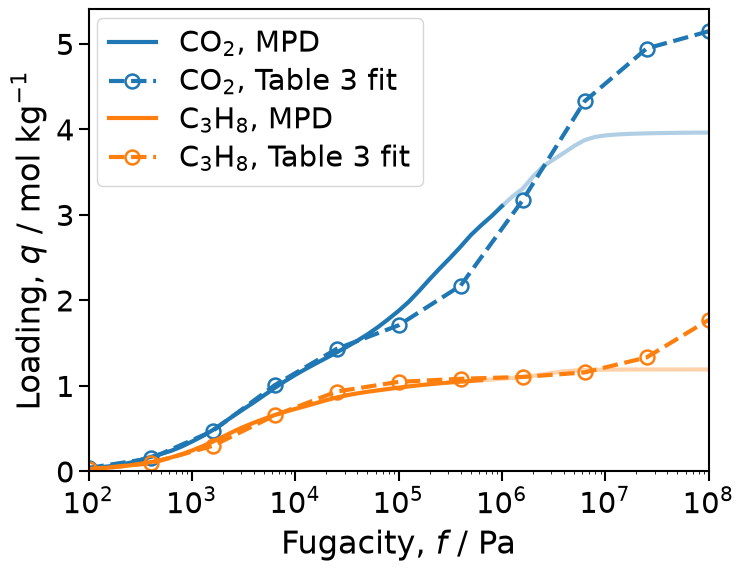

In [4]:
fig, ax = plt.subplots()
for component, fractions in {"CO2": (1.0, 0.0), "C3H8": (0.0, 1.0)}.items():
    pressure, _, loading = mixture(f"mixture_pure_{component}_MPD", component)
    trusted = np.array([frontier_probability(fractions[0] * p, fractions[1] * p) for p in pressure]) < FRONTIER_LIMIT
    top = np.flatnonzero(trusted)[-1]
    ax.plot(pressure[:top + 1], loading[:top + 1], "-", color=COLORS[component], label=f"{LABELS[component]}, MPD")
    ax.plot(pressure[top:], loading[top:], "-", color=COLORS[component], alpha=0.35)
    ax.plot(pressure[::6], langmuir(component, pressure[::6]), "--o", color=COLORS[component], markerfacecolor="none",
            label=f"{LABELS[component]}, Table 3 fit")
ax.set_xscale("log")
ax.set_xlim(1.0e2, 1.0e8)
ax.set_ylim(0.0, None)
ax.set_xlabel("Fugacity, $f$ / Pa")
ax.set_ylabel("Loading, $q$ / mol kg$^{-1}$")
ax.legend()
fig.savefig(FIGURE_DIR / "pure_isotherms.pdf", dpi=300, bbox_inches="tight")

## Sampled domain of the N-d TMMC with the equimolar MPD path

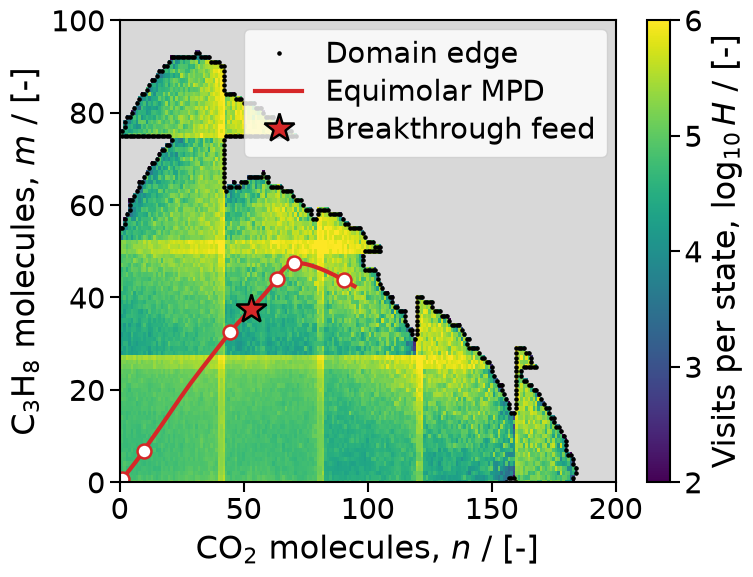

In [5]:
n, m, frontier, visits = ND_STATES[:, 0].astype(int), ND_STATES[:, 1].astype(int), ND_STATES[:, 4] == 1, ND_STATES[:, 8]
pressure, _, co2 = mixture("mixture_equimolar_MPD", "CO2")
_, _, propane = mixture("mixture_equimolar_MPD", "C3H8")
trusted = np.array([frontier_probability(0.5 * p, 0.5 * p) for p in pressure]) < FRONTIER_LIMIT
decades = [i for i in (np.argmin(np.abs(pressure - 10.0 ** k)) for k in range(2, 8)) if trusted[i]]
feed = np.argmin(np.abs(pressure - 2.0e4))

colormap = plt.get_cmap("viridis").copy()
colormap.set_bad("0.85")
shown = np.full((N_TOTAL_MAX + 1, N_PROPANE_MAX + 1), np.nan)
shown[n, m] = np.log10(np.maximum(visits, 1.0))
fig, ax = plt.subplots()
image = ax.imshow(shown.T, origin="lower", aspect="auto", cmap=colormap, vmin=2.0, vmax=6.0,
                  extent=(-0.5, N_TOTAL_MAX + 0.5, -0.5, N_PROPANE_MAX + 0.5), interpolation="nearest")
fig.colorbar(image, ax=ax, label=r"Visits per state, $\log_{10} H$ / [-]")
ax.plot(n[frontier], m[frontier], ".", color="k", markersize=3, label="Domain edge")
ax.plot(co2[trusted] * MOLECULES_PER_LOADING, propane[trusted] * MOLECULES_PER_LOADING, "-", color="C3",
        label="Equimolar MPD")
ax.plot(co2[decades] * MOLECULES_PER_LOADING, propane[decades] * MOLECULES_PER_LOADING, "o", color="C3",
        markerfacecolor="white")
ax.plot(co2[feed] * MOLECULES_PER_LOADING, propane[feed] * MOLECULES_PER_LOADING, "*", color="C3", markersize=22,
        markeredgecolor="k", label="Breakthrough feed")
ax.set_xlim(0.0, N_TOTAL_MAX)
ax.set_ylim(0.0, N_PROPANE_MAX)
ax.set_xlabel("CO$_2$ molecules, $n$ / [-]")
ax.set_ylabel("C$_3$H$_8$ molecules, $m$ / [-]")
ax.legend(loc="upper right")
fig.savefig(FIGURE_DIR / "sampling_map.pdf", dpi=300, bbox_inches="tight")

## Equimolar mixture: MPD, SIAST, and IAST

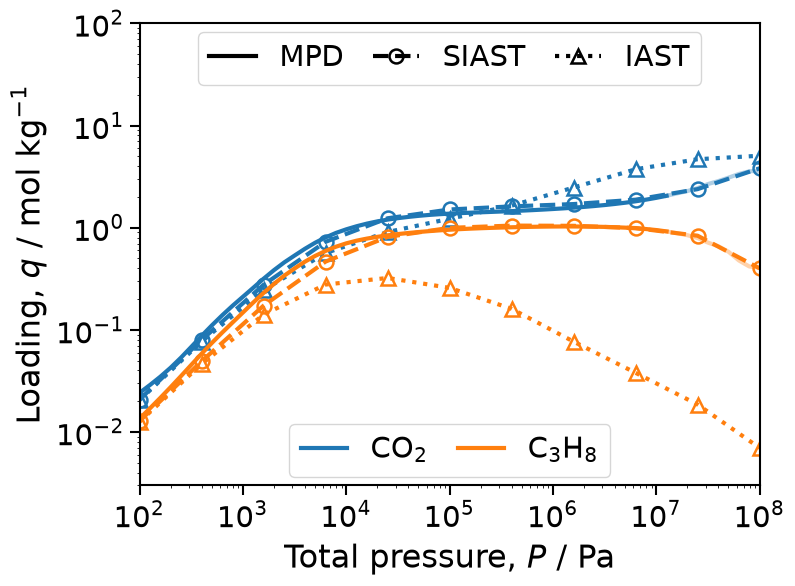

In [6]:
fig, ax = plt.subplots()
for component in COMPONENTS:
    pressure, _, loading = mixture("mixture_equimolar_SIAST", component)
    ax.plot(pressure[::6], loading[::6], "--o", color=COLORS[component], markerfacecolor="none")
    pressure, _, loading = mixture("mixture_equimolar_IAST", component)
    ax.plot(pressure[::6], loading[::6], ":^", color=COLORS[component], markerfacecolor="none")
    pressure, _, loading = mixture("mixture_equimolar_MPD", component)
    trusted = np.array([frontier_probability(0.5 * p, 0.5 * p) for p in pressure]) < FRONTIER_LIMIT
    top = np.flatnonzero(trusted)[-1]
    ax.plot(pressure[:top + 1], loading[:top + 1], "-", color=COLORS[component])
    ax.plot(pressure[top:], loading[top:], "-", color=COLORS[component], alpha=0.35)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1.0e2, 1.0e8)
ax.set_ylim(3.0e-3, 100.0)
ax.set_xlabel("Total pressure, $P$ / Pa")
ax.set_ylabel("Loading, $q$ / mol kg$^{-1}$")
methods = ax.legend(handles=[plt.Line2D([], [], color="k", linestyle="-", label="MPD"),
                             plt.Line2D([], [], color="k", linestyle="--", marker="o", markerfacecolor="none", label="SIAST"),
                             plt.Line2D([], [], color="k", linestyle=":", marker="^", markerfacecolor="none", label="IAST")],
                    ncol=3, loc="upper center")
ax.add_artist(methods)
ax.legend(handles=[plt.Line2D([], [], color=COLORS[component], label=LABELS[component]) for component in COMPONENTS],
          ncol=2, loc="lower center")
fig.savefig(FIGURE_DIR / "equimolar_mixture.pdf", dpi=300, bbox_inches="tight")

## Breakthrough (Fig. 10a of Sharma et al.) with MPD, SIAST, and IAST

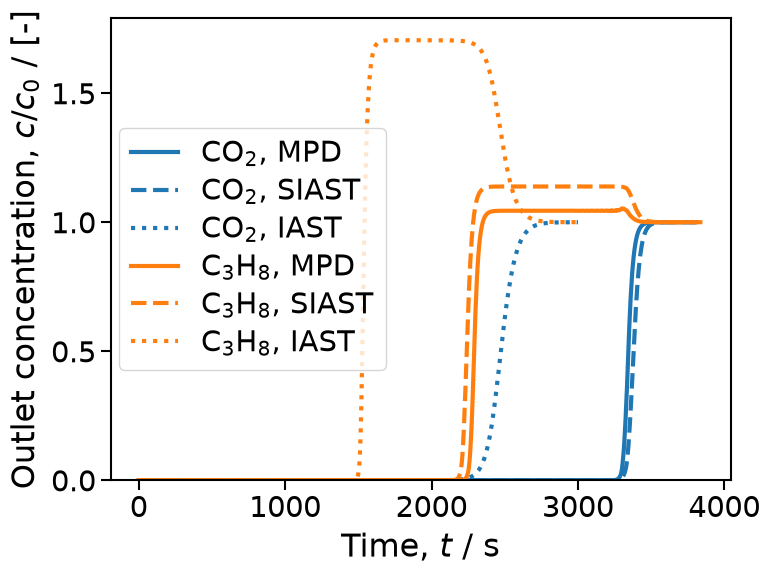

In [7]:
fig, ax = plt.subplots()
for component in COMPONENTS:
    for method, style in [("MPD", "-"), ("SIAST", "--"), ("IAST", ":")]:
        time, relative = outlet(f"breakthrough_{method}", component)
        ax.plot(time, relative, style, color=COLORS[component], label=f"{LABELS[component]}, {method}")
ax.set_xlabel("Time, $t$ / s")
ax.set_ylabel("Outlet concentration, $c/c_0$ / [-]")
ax.set_ylim(0.0, None)
ax.legend()
fig.savefig(FIGURE_DIR / "breakthrough.pdf", dpi=300, bbox_inches="tight")

## Temperature reweighting of the pure components, 300 K to 350 K

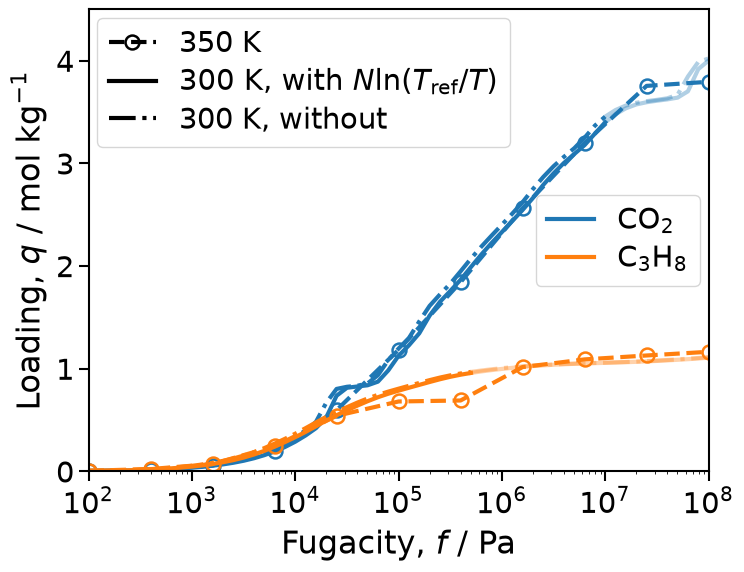

In [8]:
fig, ax = plt.subplots()
for component in COMPONENTS:
    pressure, _, direct = mixture(f"pure_{component}_MPD_T350K_ref350K", component)
    _, _, with_term = mixture(f"pure_{component}_MPD_T350K_ref300K", component)
    without_term = reweight_pure(component, 350.0, 300.0, pressure, False)
    top = np.flatnonzero(direct * MOLECULES_PER_LOADING <= SAMPLED_MOLECULES_350K[component])[-1]
    for loading, style in [(with_term, "-"), (without_term, "-.")]:
        ax.plot(pressure[:top + 1], loading[:top + 1], style, color=COLORS[component])
        ax.plot(pressure[top:], loading[top:], style, color=COLORS[component], alpha=0.35)
    ax.plot(pressure[::6], direct[::6], "--o", color=COLORS[component], markerfacecolor="none")
ax.set_xscale("log")
ax.set_xlim(1.0e2, 1.0e8)
ax.set_ylim(0.0, 4.5)
ax.set_xlabel("Fugacity, $f$ / Pa")
ax.set_ylabel("Loading, $q$ / mol kg$^{-1}$")
methods = ax.legend(handles=[plt.Line2D([], [], color="k", linestyle="--", marker="o", markerfacecolor="none", label="350 K"),
                             plt.Line2D([], [], color="k", linestyle="-", label=r"300 K, with $N\ln(T_\mathrm{ref}/T)$"),
                             plt.Line2D([], [], color="k", linestyle="-.", label="300 K, without")],
                    loc="upper left")
ax.add_artist(methods)
ax.legend(handles=[plt.Line2D([], [], color=COLORS[component], label=LABELS[component]) for component in COMPONENTS],
          loc="center right")
fig.savefig(FIGURE_DIR / "reweighting_350K.pdf", dpi=300, bbox_inches="tight")

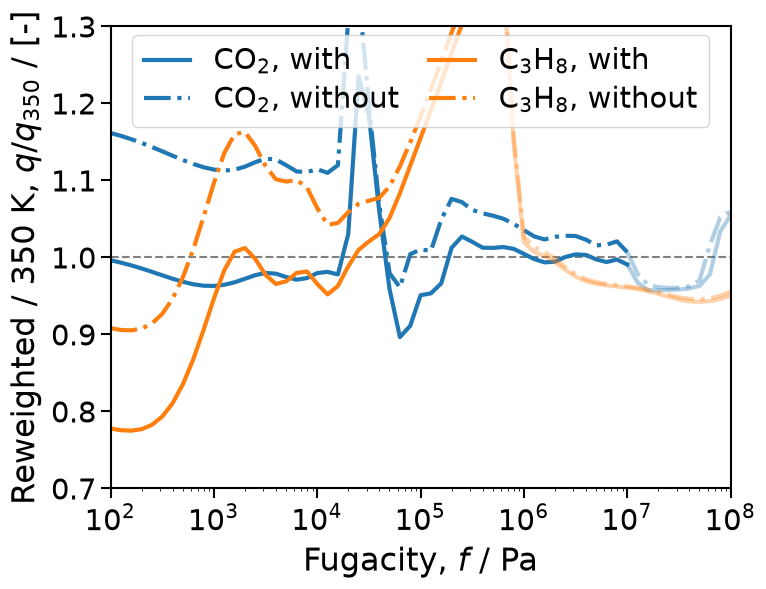

In [9]:
fig, ax = plt.subplots()
ax.axhline(1.0, color="0.5", linestyle="--", linewidth=1.5)
for component in COMPONENTS:
    pressure, _, direct = mixture(f"pure_{component}_MPD_T350K_ref350K", component)
    _, _, with_term = mixture(f"pure_{component}_MPD_T350K_ref300K", component)
    without_term = reweight_pure(component, 350.0, 300.0, pressure, False)
    top = np.flatnonzero(direct * MOLECULES_PER_LOADING <= SAMPLED_MOLECULES_350K[component])[-1]
    for loading, style, label in [(with_term, "-", "with"), (without_term, "-.", "without")]:
        ratio = loading / direct
        ax.plot(pressure[:top + 1], ratio[:top + 1], style, color=COLORS[component], label=f"{LABELS[component]}, {label}")
        ax.plot(pressure[top:], ratio[top:], style, color=COLORS[component], alpha=0.35)
ax.set_xscale("log")
ax.set_xlim(1.0e2, 1.0e8)
ax.set_ylim(0.7, 1.3)
ax.set_xlabel("Fugacity, $f$ / Pa")
ax.set_ylabel("Reweighted / 350 K, $q/q_{350}$ / [-]")
ax.legend(ncol=2, loc="upper center")
fig.savefig(FIGURE_DIR / "reweighting_ratio.pdf", dpi=300, bbox_inches="tight")